# 01 — Data Understanding & Data Preparation
Output: `data/dki_master.csv` (1 baris = 1 kecamatan)

## 0. Setup

In [1]:
import re, csv, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, geopandas as gpd
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

ROOT = Path("..")
RAW, DATA = ROOT/"data/raw", ROOT/"data"
INT = DATA/"interim"; INT.mkdir(parents=True, exist_ok=True)
read = lambda key: pd.read_html(next(RAW.glob(f"*{key}*.xls")), flavor="lxml")[0]    # file .xls dari Satu Data Jakarta = HTML table

# A. DATA UNDERSTANDING

## A1. Inventaris file

In [2]:
inv = pd.DataFrame([{"file": f.name[:70], "ukuran_KB": round(f.stat().st_size/1024), "isi": f.read_bytes()[:15].decode(errors="ignore").strip()} for f in sorted(f for f in RAW.iterdir() if f.is_file())])
inv

,file,ukuran_KB,isi
0,data-kejadian-bencana-banjir-di-provinsi-dki-j...,71,<html>\n <head>
1,data-kejadian-bencana-banjir-di-provinsi-dki-j...,46,<html>\n <head>
2,data-kejadian-bencana-banjir-di-provinsi-dki-j...,244,<html>\n <head>
3,data-kejadian-bencana-banjir-tahun-2013-di-dki...,74,<html>\n <head>
4,data-kejadian-bencana-banjir-tahun-2014-di-dki...,74,<html>\n <head>
5,data-kejadian-bencana-banjir-tahun-2015-di-dki...,60,<html>\n <head>
6,data-kejadian-bencana-banjir-tahun-2016-di-dki...,84,<html>\n <head>
7,data-kejadian-bencana-banjir-tahun-2024-kompon...,60,<html>\n <head>
8,data-kepadatan-dan-luas-wilayah-per-kelurahan-...,275,<html>\r\n <head
9,data-meteorologi-komponen-data.xls,33268,<html>\n <head>


## A2. Kepadatan & luas wilayah

In [3]:
dens_raw = read("kepadatan")
print(dens_raw.shape); display(dens_raw.head()); display(dens_raw.dtypes.to_frame("dtype").T)
print("missing:", int(dens_raw.isna().sum().sum()), "| tahun:", sorted(dens_raw.periode_data.unique()),
      "| kecamatan:", dens_raw.nama_kecamatan.nunique(), "| kelurahan:", dens_raw.nama_kelurahan.nunique())
dens_raw.describe().round(2)

(1869, 7)


,periode_data,nama_provinsi,nama_kabupaten_kota,nama_kecamatan,nama_kelurahan,luas_wilayah_km2,kepadatan_jiwa_km2
0,2013,PROVINSI DKI JAKARTA,JAKARTA PUSAT,JOHAR BARU,KAMPUNG RAWA,0.30,86123
1,2013,PROVINSI DKI JAKARTA,JAKARTA PUSAT,JOHAR BARU,GALUR,0.27,79022
2,2013,PROVINSI DKI JAKARTA,JAKARTA PUSAT,JOHAR BARU,TANAH TINGGI,0.62,71177
3,2013,PROVINSI DKI JAKARTA,JAKARTA UTARA,PENJARINGAN,PENJARINGAN,3.95,28071
4,2013,PROVINSI DKI JAKARTA,JAKARTA UTARA,PENJARINGAN,KAMAL MUARA,10.53,1144


,periode_data,nama_provinsi,nama_kabupaten_kota,nama_kecamatan,nama_kelurahan,luas_wilayah_km2,kepadatan_jiwa_km2
dtype,int64,object,object,object,object,float64,int64


missing: 0 | tahun: [np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)] | kecamatan: 44 | kelurahan: 267


,periode_data,luas_wilayah_km2,kepadatan_jiwa_km2
count,1869.0,1869.00,1869.00
mean,2016.0,18.86,23373.45
std,2.0,69.23,20730.93
min,2013.0,0.26,624.00
25%,2014.0,0.98,12211.00
50%,2016.0,2.68,17806.00
75%,2018.0,15.04,29756.00
max,2019.0,981.04,307643.00


{2013: 664.0, 2014: 664.0, 2015: 6785.0, 2016: 6785.0, 2017: 6785.0, 2018: 6785.0, 2019: 6785.0}
rasio luas 2015/2014 per kelurahan: {0.0: 1, 1.0: 146, 2.0: 2, 3.0: 1, 4.0: 1, 6.0: 1, 7.0: 2, 8.0: 4, 9.0: 5, 10.0: 87, 11.0: 4, 12.0: 3} ...


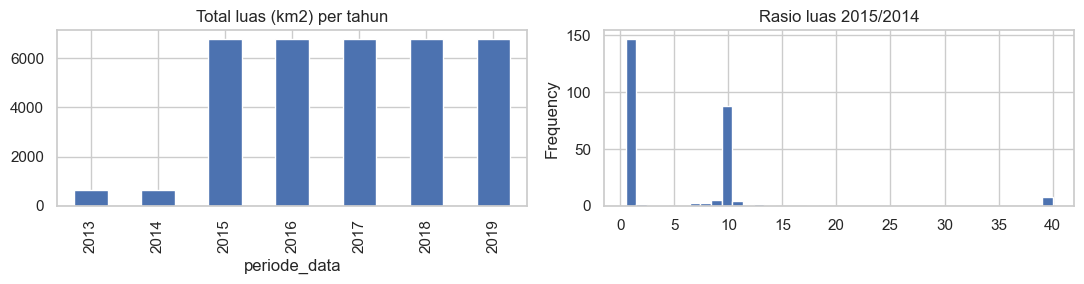

In [4]:
# Cek konsistensi: total luas DKI seharusnya ~662 km2 setiap tahun
tot = dens_raw.groupby("periode_data").luas_wilayah_km2.sum().round(0); print(tot.to_dict())
w = dens_raw.pivot_table(index="nama_kelurahan", columns="periode_data", values="luas_wilayah_km2")
ratio = (w[2015] / w[2014]).round(1)
print("rasio luas 2015/2014 per kelurahan:", ratio.round(0).value_counts().sort_index().head(12).to_dict(), "...")
fig, ax = plt.subplots(1, 2, figsize=(11, 3)); tot.plot.bar(ax=ax[0], title="Total luas (km2) per tahun"); ratio.clip(upper=40).plot.hist(bins=40, ax=ax[1], title="Rasio luas 2015/2014")
plt.tight_layout(); plt.show()

> **Temuan:** luas 2015–2019 rusak tidak seragam (total ×10; sebagian kelurahan tetap, sebagian ×10 sampai ×100). Luas 2013–2014 valid.

## A3. Kejadian banjir per kelurahan (8 file, 2013–2024)

In [5]:
flood_files = {int(re.search(r"20\d\d", f.name).group()): f for f in sorted(RAW.glob("*kejadian-bencana-banjir*.xls"))}
fl_raw = {y: pd.read_html(f, flavor="lxml")[0] for y, f in flood_files.items()}
pd.DataFrame({y: {"baris": len(x), "kolom": x.shape[1], "kecamatan_unik": x.kecamatan.nunique(), "kelurahan_unik": x.kelurahan.nunique(),
                  "missing_%": round(x.isna().mean().mean()*100, 1)} for y, x in fl_raw.items()}).T

,baris,kolom,kecamatan_unik,kelurahan_unik,missing_%
2017,264.0,19.0,59.0,139.0,1.3
2019,167.0,19.0,33.0,94.0,0.0
2020,902.0,19.0,46.0,219.0,0.0
2013,245.0,21.0,40.0,142.0,0.1
2014,268.0,19.0,38.0,140.0,2.5
2015,217.0,19.0,42.0,146.0,0.0
2016,316.0,19.0,34.0,117.0,0.0
2024,260.0,16.0,29.0,92.0,0.0


In [6]:
# Skema kolom berbeda tiap tahun
cols = sorted(set().union(*[set(x.columns) for x in fl_raw.values()]))
schema = pd.DataFrame({y: [("v" if col in x.columns else "") for col in cols] for y, x in fl_raw.items()}, index=cols)
schema

,2017,2019,2020,2013,2014,2015,2016,2024
bulan,,,,,,,,v
jumlah_hilang,v,v,v,v,v,v,v,
jumlah_jiwa,,,,,v,v,,
jumlah_jiwa_terdampak,,,,,,,,v
jumlah_kejadian,,,,,,,,v
jumlah_kk,,,,,v,v,,
jumlah_kk_terdampak,,,,,,,,v
jumlah_korban_luka,,,,,,,,v
jumlah_korban_meninggal,,,,,,,,v
jumlah_luka_berat,v,v,v,v,v,v,v,


In [7]:
# Contoh isi mentah kolom penting
for y in [2013, 2017, 2020, 2024]:
    x = fl_raw[y]; col_t = "ketinggian_air" if "ketinggian_air" in x else "jumlah_rata_rata_ketinggian_air"
    print(y, "| ketinggian:", x[col_t].dropna().astype(str).unique()[:5].tolist(), "| periode_data:", x.periode_data.astype(str).unique()[:4].tolist())

2013 | ketinggian: ['20 - 250', '30 - 400', '30 - 260', '40 - 300', '30 - 150'] | periode_data: ['201301', '201302', '201303', '201304']
2017 | ketinggian: ['10 S/D 70 CM', '20 S/D 80 CM', '70 S/D 100 CM', '40 S/D 70 CM', '10 S/D 60 CM'] | periode_data: ['201710', '201712', '201702', '201703']
2020 | ketinggian: ['31 S/D 150 CM', '31 S/D 70 CM', '10 S/D 150 CM', '31 S/D 100 CM', '10 S/D 140 CM'] | periode_data: ['202001', '202002', '202008', '202003']
2024 | ketinggian: ['10 S.D 60 CM', '30 S.D 40 CM', '30 CM', '30 S.D 100 CM', '40 CM'] | periode_data: ['202406', '202403', '202412', '202409']


In [8]:
# Granularitas: file 2020 per-RW (banyak baris per kelurahan), file lain per-kelurahan
for y in [2017, 2020]:
    x = fl_raw[y]; print(y, "| baris:", len(x), "| baris per kelurahan-periode (rata2):", round(len(x) / x.groupby(["periode_data","kelurahan"]).ngroups, 2))
display(fl_raw[2020][["periode_data","kecamatan","kelurahan","rw","tanggal_kejadian"]].head(6))
# Nama kecamatan kotor
bad = sorted({str(k) for x in fl_raw.values() for k in x.kecamatan.dropna().unique()})
print(len(bad), "variasi nama kecamatan mentah, contoh:", bad[:8], "...", [b for b in bad if "KOSONG" in b or "SERIBU" in b][:4])

2017 | baris: 264 | baris per kelurahan-periode (rata2): 1.0
2020 | baris: 902 | baris per kelurahan-periode (rata2): 1.57


,periode_data,kecamatan,kelurahan,rw,tanggal_kejadian
0,202001,KALIDERES,TEGAL ALUR,"RW 03, 04, 11, 12, 15",TGL. 01 JANUARI
1,202001,KEBON JERUK,DURI KEPA,"'RW 02, 03, 04, 05, 09, 13, 14",TGL. 01 JANUARI
2,202001,KEBON JERUK,KEDOYA SELATAN,"RW 01, 04, 05","TGL. 01, 27 JANUARI"
3,202001,KEBON JERUK,KEDOYA UTARA,"RW 02, 04, 05",TGL. 01 JANUARI
4,202001,KEBON JERUK,SUKABUMI UTARA,"RW 01, 03, 04, 07, 08, 10, 11","TGL. 01, 18 JANUARI"
5,202001,KEBON JERUK,SUKABUMI SELATAN,"RW 01, 02, 04, 08",TGL. 18 JANUARI


97 variasi nama kecamatan mentah, contoh: ['CAKUNG', 'CEMPAKA PUTIH', 'CENGKARENG', 'CILANDAK', 'CILIINCING', 'CILINCING', 'CIPAYUNG', 'CIRACAS'] ... ['KEP. SERIBU SELATAN', 'KEP. SERIBU UTARA', 'KEPULAUAN SERIBU SELATAN', 'KEPULAUAN SERIBU UTARA']


> **Temuan:** skema beda tiap tahun · 2018 & 2021–2023 tidak ada · file 2020 per-RW · nama kecamatan kotor (awalan `KEC.`, salah ketik, `KOSONG`) · ketinggian air terbaca tanggal oleh Excel (`OCT-80` = `10-80`) · periode ganjil (`202131`).

## A4. Rekap banjir provinsi (bulanan)

In [9]:
rk = read("rekapitulasi-tahunan"); print(rk.shape); display(rk.iloc[:6, :9])
print("kecamatan max:", rk.kecamatan.max(), "| dtype:", rk.kecamatan.dtype)

(95, 16)


,periode_data,bulan,kecamatan,kelurahan,rata_rata_ketinggian_air,lama_genangan,rw_terdampak,kk_terdampak,jiwa_terdampak
0,2015,1,15.0,36.0,10 - 150,2,221.0,6095,13073
1,2015,2,38.0,133.0,10 - 200,7,615.0,64458,231566
2,2015,3,12.0,15.0,10 - 200,4,30.0,2869,8119
3,2015,4,4.0,6.0,20 - 100,3,18.0,2235,7905
4,2015,5,1.0,1.0,20 - 100,1,7.0,423,2088
5,2015,6,0.0,0.0,0,0,0.0,0,0


kecamatan max: 42.0 | dtype: float64


> **Temuan:** kolom `kecamatan`/`kelurahan` di sini berisi **jumlah**, bukan nama → hanya dipakai untuk validasi silang, bukan fitur kecamatan.

## A5. Alat peringatan dini

In [10]:
al_raw = read("alat-peringatan"); print(al_raw.shape); display(al_raw.head(4))
print("longitude:", al_raw.longitude.min().round(2), "-", al_raw.longitude.max().round(2), "| latitude:", al_raw.latitude.min().round(2), "-", al_raw.latitude.max().round(2))
print("titik unik:", al_raw[["longitude","latitude"]].drop_duplicates().shape[0], "dari", len(al_raw), "baris | tahun:", al_raw.periode_data.unique().tolist())

(26, 5)


,periode_data,lokasi,longitude,latitude,jumlah
0,2024,JL. SUKA MENANTI RT 04 RW 11 RAWA BUAYA CENGKA...,-6.159725,106.745117,1
1,2024,JL.KP.BARU NO 77 TITIK LOKASI RPTRA KAMPUNG BARU,-6.166489,106.752684,1
2,2024,JL. CILEDUG RAYA NO 11A CIPULIS JAKSEL TITIK L...,-6.238935,106.766347,1
3,2024,JL. BERDIKARI 1 NO 58 KAPUK CENGKARENG JAKBAR,-6.142817,106.768891,1


longitude: -6.29 - -6.14 | latitude: 106.75 - 106.89
titik unik: 13 dari 26 baris | tahun: [2024, 2025]


> **Temuan:** kolom longitude/latitude **tertukar** (longitude ≈ −6, latitude ≈ 106) · 26 baris = 13 titik × 2 tahun · tanpa kolom kecamatan.

## A6. Faskes, SDA, meteorologi

In [11]:
fk = read("fasilitas-kesehatan"); sd = read("infrastruktur-sumber-daya-air")
print("faskes:", fk.shape, "| wilayah:", fk.wilayah.unique()[:7].tolist(), "| tahun:", sorted(fk.periode_data.unique()))
print("sda   :", sd.shape, "| tahun:", sd.periode_data.unique().tolist(), "| kolom lokasi: tidak ada")
met = next(RAW.glob("*meteorologi*.xls"), None); print("meteorologi:", None if met is None else f"{met.stat().st_size/1e6:.0f} MB")

faskes: (95, 4) | wilayah: ['DKI JAKARTA', 'KOTA ADM. JAKARTA BARAT', 'KOTA ADM. JAKARTA PUSAT', 'KOTA ADM. JAKARTA SELATAN', 'KOTA ADM. JAKARTA TIMUR', 'KOTA ADM. JAKARTA UTARA', 'KAB. ADM. KEP. SERIBU'] | tahun: [np.int64(2023), np.int64(2024), np.int64(2025)]
sda   : (26, 4) | tahun: [2025] | kolom lokasi: tidak ada
meteorologi: 34 MB


## A7. Ringkasan: dataset mana yang bisa jadi fitur kecamatan?

In [12]:
pd.DataFrame([
 ["Kepadatan & luas", "kelurahan", "2013–2019", "Ya (agregasi ke kecamatan)", "luas 2015+ rusak"],
 ["Banjir per kelurahan", "kelurahan/RW", "8 dari 12 tahun", "Ya (fitur utama)", "skema beda, nama kotor, 2020 per-RW"],
 ["Rekap banjir provinsi", "provinsi", "2013–2020", "Tidak (validasi)", "kolom kecamatan = jumlah"],
 ["Alat peringatan dini", "titik koordinat", "2024–2025", "Ya (spatial join)", "lat/lon tertukar, duplikat"],
 ["Faskes", "kota", "2023–2025", "Tidak", "tidak sampai kecamatan"],
 ["SDA", "provinsi", "2025", "Tidak", "tanpa lokasi"],
 ["Meteorologi", "belum diperiksa", "?", "?", "file besar"]],
 columns=["dataset","level","tahun","fitur kecamatan?","masalah"])

,dataset,level,tahun,fitur kecamatan?,masalah
0,Kepadatan & luas,kelurahan,2013–2019,Ya (agregasi ke kecamatan),luas 2015+ rusak
1,Banjir per kelurahan,kelurahan/RW,8 dari 12 tahun,Ya (fitur utama),"skema beda, nama kotor, 2020 per-RW"
2,Rekap banjir provinsi,provinsi,2013–2020,Tidak (validasi),kolom kecamatan = jumlah
3,Alat peringatan dini,titik koordinat,2024–2025,Ya (spatial join),"lat/lon tertukar, duplikat"
4,Faskes,kota,2023–2025,Tidak,tidak sampai kecamatan
5,SDA,provinsi,2025,Tidak,tanpa lokasi
6,Meteorologi,belum diperiksa,?,?,file besar


# B. DATA PREPARATION

## B1. Kepadatan → kecamatan

In [13]:
d = dens_raw.rename(columns={"nama_kecamatan":"kecamatan","nama_kelurahan":"kelurahan","nama_kabupaten_kota":"wilayah"}).copy()
for col in ["kecamatan","kelurahan","wilayah"]: d[col] = d[col].str.strip().str.upper()

# luas dikunci ke 2014 (valid), kepadatan tahunan dipakai apa adanya
ref = d[d.periode_data == 2014].set_index(["kecamatan","kelurahan"]).luas_wilayah_km2.rename("luas_km2")
d = d.join(ref, on=["kecamatan","kelurahan"]); d["penduduk"] = d.luas_km2 * d.kepadatan_jiwa_km2
print("total luas setelah perbaikan:", d.groupby("periode_data").luas_km2.sum().round(0).to_dict())
print("total penduduk (juta):", (d.groupby("periode_data").penduduk.sum()/1e6).round(2).to_dict())

total luas setelah perbaikan: {2013: 664.0, 2014: 664.0, 2015: 664.0, 2016: 664.0, 2017: 664.0, 2018: 664.0, 2019: 664.0}
total penduduk (juta): {2013: 9.99, 2014: 10.02, 2015: 11.27, 2016: 11.39, 2017: 11.43, 2018: 11.09, 2019: 11.31}


In [14]:
dens = (d.groupby(["periode_data","wilayah","kecamatan"], as_index=False)
          .agg(luas_km2=("luas_km2","sum"), penduduk=("penduduk","sum"), n_kelurahan=("kelurahan","nunique")))
dens["kepadatan_jiwa_km2"] = dens.penduduk / dens.luas_km2          # pop / area (bukan rata-rata kelurahan)

nkey = lambda s: re.sub(r"[^A-Z]", "", re.sub(r"^(KECAMATAN|KELURAHAN)\s+|^(KEC|KEL)\.\s*", "", str(s).upper().strip()))   # kunci nama: huruf saja
KEC_BAKU   = sorted(d.kecamatan.unique());  KEC_BY_KEY = {nkey(k): k for k in KEC_BAKU}
KEL2KEC    = {nkey(r.kelurahan): r.kecamatan for r in d.drop_duplicates("kelurahan").itertuples()}
print(len(KEC_BAKU), "kecamatan baku |", len(KEL2KEC), "kelurahan"); dens.query("periode_data==2019").head(3)

44 kecamatan baku | 267 kelurahan


,periode_data,wilayah,kecamatan,luas_km2,penduduk,n_kelurahan,kepadatan_jiwa_km2
264,2019,JAKARTA BARAT,CENGKARENG,27.93,612880.43,6,21943.445399
265,2019,JAKARTA BARAT,GROGOL PETAMBURAN,11.46,246399.94,7,21500.867365
266,2019,JAKARTA BARAT,KALI DERES,29.08,415566.68,5,14290.463549


## B2. Banjir per kelurahan

### B2a. Satu skema kolom

In [15]:
CANDS = {"kk_terdampak":["jumlah_terdampak_kk","jumlah_kk_terdampak","jumlah_kk"],
         "jiwa_terdampak":["jumlah_terdampak_jiwa","jumlah_jiwa_terdampak","jumlah_jiwa"],
         "tinggi_raw":["ketinggian_air","jumlah_rata_rata_ketinggian_air"], "lama_raw":["lama_genangan"],
         "pengungsi":["jumlah_pengungsi_tertinggi","jumlah_pengungsi"], "n_kejadian":["jumlah_kejadian"]}
pick = lambda df, names: next((df[n] for n in names if n in df.columns), pd.Series(np.nan, index=df.index))

parts = []
for y, x in fl_raw.items():
    o = pd.DataFrame({k: pick(x, v) for k, v in CANDS.items()})
    o["kecamatan_raw"], o["kelurahan_raw"], o["periode_raw"], o["file_tahun"] = x["kecamatan"], x["kelurahan"], x["periode_data"], y
    o["bulan_file"] = pd.to_numeric(x["bulan"], errors="coerce") if "bulan" in x else np.nan
    parts.append(o)
fl = pd.concat(parts, ignore_index=True); print(fl.shape); fl.head(3)

(2639, 11)


,kk_terdampak,jiwa_terdampak,tinggi_raw,lama_raw,pengungsi,n_kejadian,kecamatan_raw,kelurahan_raw,periode_raw,file_tahun,bulan_file
0,0,0,10 S/D 70 CM,0,0,NaN,KEC. KEBON JERUK,KEL. SUKABUMI SELATAN,201710,2017,NaN
1,0,0,20 S/D 80 CM,0,0,NaN,KEC. MAMPANG PRAPATAN,KEL. BANGKA,201710,2017,NaN
2,0,0,70 S/D 100 CM,0,0,NaN,KEC. PANCORAN,KEL. PANCORAN,201710,2017,NaN


### B2b. Normalisasi nama kecamatan

In [16]:
ALIAS = {"MARAMAN":"MATRAMAN","PESANGRAHAN":"PESANGGRAHAN","PESANGGARAHAN":"PESANGGRAHAN","CILIINCING":"CILINCING","JAGAKARTA":"JAGAKARSA",
         "MAKASSAR":"MAKASAR","MAMPANG":"MAMPANGPRAPATAN","PADEMANGANBARAT":"PADEMANGAN","PADEMANGANTIMUR":"PADEMANGAN","KEDOYASELATAN":"KEBONJERUK",
         "KEPULAUANSERIBUSELATAN":"KEPSERIBUSLT","KEPSERIBUSELATAN":"KEPSERIBUSLT","KEPULAUANSERIBUUTARA":"KEPSERIBUUTR","KEPSERIBUUTARA":"KEPSERIBUUTR"}
def canon_kec(kec, kel):
    k = ALIAS.get(nkey(kec), nkey(kec))
    return KEC_BY_KEY[k] if k in KEC_BY_KEY else KEL2KEC.get(ALIAS.get(nkey(kel), nkey(kel)))     # fallback lewat nama kelurahan

fl["kecamatan"] = [canon_kec(a, b) for a, b in zip(fl.kecamatan_raw, fl.kelurahan_raw)]
print("sebelum: cocok baku langsung =", int(fl.kecamatan_raw.map(lambda s: nkey(s) in KEC_BY_KEY).sum()), "/", len(fl))
print("sesudah: cocok =", int(fl.kecamatan.notna().sum()), "/", len(fl), "| dibuang:", int(fl.kecamatan.isna().sum()), fl[fl.kecamatan.isna()].kecamatan_raw.value_counts().head(3).to_dict())
fl = fl.dropna(subset=["kecamatan"]).copy()

sebelum: cocok baku langsung = 2570 / 2639
sesudah: cocok = 2621 / 2639 | dibuang: 18 {'KOSONG': 2}


### B2c. Parsing angka (ketinggian, lama genangan, jiwa, dst.)

In [17]:
MONTH_FIX = {"OCT":10,"MAY":5,"JAN":1,"FEB":2,"MAR":3,"APR":4,"JUN":6,"JUL":7,"AUG":8,"SEP":9,"NOV":11,"DEC":12}   # Excel: "10-80" -> "OCT-80"
def nums(t):
    if pd.isna(t): return []
    t = str(t).upper()
    for k, v in MONTH_FIX.items(): t = t.replace(k, str(v))
    return [float(x) for x in re.findall(r"\d+(?:[.,]\d+)?", t.replace(",", "."))]
num_max = lambda t: (max(nums(t)) if nums(t) else np.nan)
to_num  = lambda s: pd.to_numeric(s.astype(str).str.upper().replace({"N.A":np.nan,"N/A":np.nan,"-":np.nan,"KOSONG":np.nan,"NAN":np.nan}), errors="coerce")

fl["tinggi_max_cm"] = fl.tinggi_raw.map(num_max); fl["lama_hari"] = fl.lama_raw.map(num_max)
for col in ["kk_terdampak","jiwa_terdampak","pengungsi","n_kejadian"]: fl[col] = to_num(fl[col])
print(pd.DataFrame({"mentah": ["OCT-80","MAY-40","10 S.D 70 CM","5 - 360","31 S/D 150 CM"], "hasil_max": [num_max(s) for s in ["OCT-80","MAY-40","10 S.D 70 CM","5 - 360","31 S/D 150 CM"]]}).T.to_string(header=False))
fl[["tinggi_raw","tinggi_max_cm","lama_raw","lama_hari"]].dropna().sample(5, random_state=1)

mentah     OCT-80  MAY-40  10 S.D 70 CM  5 - 360  31 S/D 150 CM
hasil_max    80.0    40.0          70.0    360.0          150.0


,tinggi_raw,tinggi_max_cm,lama_raw,lama_hari
56,100 - 120 CM,120.0,0,0.0
589,10 S/D 70 CM,70.0,0,0.0
1701,10 - 60,60.0,11.0,11.0
2027,0 - 60,60.0,2,2.0
477,71 S/D 150 CM,150.0,0,0.0


### B2d. Tahun & bulan

In [18]:
per = fl.periode_raw.astype(str).str[:6]; yr = pd.to_numeric(per.str[:4], errors="coerce"); mo = pd.to_numeric(per.str[4:6], errors="coerce")
ok = (yr - fl.file_tahun).abs() <= 1                                  # tolak periode ganjil (202131); file 2020 memuat Okt-Des 2019
fl["tahun"] = np.where(ok, yr, fl.file_tahun)
fl["bulan"] = np.where(ok & mo.between(1, 12), mo, np.nan)
fl["bulan"] = fl.bulan_file.fillna(pd.Series(fl.bulan, index=fl.index))   # file 2024: pakai kolom bulan (periode = akhir triwulan)
print("periode ditolak:", int((~ok).sum()), "| tahun:", fl.groupby("tahun").size().to_dict(), "| bulan NaN:", int(fl.bulan.isna().sum()))

periode ditolak: 15 | tahun: {2013: 245, 2014: 252, 2015: 217, 2016: 314, 2017: 264, 2019: 575, 2020: 494, 2024: 260} | bulan NaN: 15


### B2e. Samakan granularitas → 1 baris = 1 kelurahan-bulan

In [19]:
fl["kel_key"] = fl.kelurahan_raw.map(nkey)
flood = (fl.groupby(["file_tahun","tahun","bulan","kecamatan","kel_key"], dropna=False)
           .agg(jiwa_terdampak=("jiwa_terdampak","sum"), kk_terdampak=("kk_terdampak","sum"), tinggi_max_cm=("tinggi_max_cm","max"),
                lama_hari=("lama_hari","max"), pengungsi=("pengungsi","sum"), n_kejadian=("n_kejadian","sum")).reset_index())
flood.loc[flood.n_kejadian == 0, "n_kejadian"] = 1                    # file selain 2024: 1 baris = 1 kejadian
print("baris:", len(fl), "->", len(flood)); print(pd.DataFrame({"sebelum": fl.groupby("tahun").size(), "sesudah": flood.groupby("tahun").size()}).T)

baris: 2621 -> 2295
tahun    2013  2014  2015  2016  2017  2019  2020  2024
sebelum   245   252   217   314   264   575   494   260
sesudah   245   252   217   314   264   249   494   260


### B2f. Buang duplikat antar file

In [20]:
dup = flood.sort_values("file_tahun").duplicated(["tahun","bulan","kecamatan","kel_key"], keep="first")      # 2020 memuat Okt-Des 2019
flood = flood[~dup.reindex(flood.index, fill_value=False)].drop(columns="file_tahun").reset_index(drop=True)
flood.to_csv(INT/"banjir_kelurahan_clean.csv", index=False)
print("duplikat dibuang:", int(dup.sum()), "| akhir:", flood.shape, "| tahun:", [int(t) for t in sorted(flood.tahun.unique())], "| kecamatan:", flood.kecamatan.nunique())

duplikat dibuang: 8 | akhir: (2287, 10) | tahun: [2013, 2014, 2015, 2016, 2017, 2019, 2020, 2024] | kecamatan: 44


### B2g. Validasi vs rekap provinsi

In [21]:
bm = flood.dropna(subset=["bulan"]).groupby("tahun").bulan.apply(lambda s: sorted({int(m_) for m_ in s}))
rm = rk[rk.kecamatan.fillna(0) > 0].groupby("periode_data").bulan.apply(lambda s: sorted({int(m_) for m_ in s}))
cmp_ = pd.DataFrame({"file_kelurahan": bm, "rekap_provinsi": rm}); cmp_["cocok"] = cmp_.file_kelurahan == cmp_.rekap_provinsi; cmp_

,file_kelurahan,rekap_provinsi,cocok
2013,"[1, 2, 3, 4, 5, 6, 7, 8, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12]",False
2014,"[1, 2, 3, 4, 5, 6, 7, 8, 11, 12]","[1, 2, 3, 4, 5, 6, 7, 8, 11, 12]",True
2015,"[1, 2, 3, 4, 5, 11, 12]","[1, 2, 3, 4, 5, 11, 12]",True
2016,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]",False
2017,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",True
2018,NaN,"[1, 2, 3, 4, 5, 6, 10, 11, 12]",False
2019,"[1, 2, 3, 4, 5, 10, 12]","[1, 2, 3, 4, 5, 10, 12]",True
2020,"[1, 2, 3, 4, 5, 6, 7, 8, 9]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",False
2024,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12]",NaN,False


> Beda = bulan hilang di file per kelurahan (mis. 2020 berhenti September). Dicatat sebagai keterbatasan.

## B3. Alat peringatan dini

In [22]:
al = al_raw.rename(columns={"longitude":"lat","latitude":"lon"})       # perbaiki kolom tertukar
assert al.lat.between(-7, -5).all() and al.lon.between(106, 107.5).all()
al = al.drop_duplicates(["lokasi","lat","lon"]).drop(columns="periode_data").reset_index(drop=True); print(len(al_raw), "->", len(al), "titik")

26 -> 13 titik


In [23]:
pol = gpd.read_file(RAW/"kecamatan.geojson").to_crs(4326)
pol["kecamatan"] = [KEC_BY_KEY.get(ALIAS.get(nkey(n), nkey(n)), n) for n in pol["name"]]
print("poligon:", len(pol), "| tidak cocok dengan 44 baku:", [n for n in pol.kecamatan if n not in KEC_BAKU])
pol[["kecamatan","geometry"]].to_file(INT/"kecamatan_poly.geojson", driver="GeoJSON")

pts = gpd.GeoDataFrame(al, geometry=gpd.points_from_xy(al.lon, al.lat), crs=4326)
j = gpd.sjoin(pts, pol[["kecamatan","geometry"]], how="left", predicate="within").drop(columns="index_right")
miss = j.kecamatan.isna()
if miss.any():                                                          # titik di luar poligon -> kecamatan terdekat
    jn = gpd.sjoin_nearest(pts[miss].to_crs(32748), pol[["kecamatan","geometry"]].to_crs(32748), how="left"); j.loc[miss, "kecamatan"] = jn.kecamatan.values
alat = j.drop(columns="geometry"); alat.to_csv(INT/"alat_dini_titik.csv", index=False)
alat_per_kec = alat.groupby("kecamatan").size().rename("n_alat_dini"); print("di luar poligon:", int(miss.sum())); alat_per_kec.to_frame().T

poligon: 42 | tidak cocok dengan 44 baku: []
di luar poligon: 0


kecamatan,CENGKARENG,JATINEGARA,KEBAYORAN BARU,KEBAYORAN LAMA,KEMBANGAN,KRAMAT JATI,MAKASAR,PANCORAN,PASAR MINGGU,TEBET
n_alat_dini,2,2,1,1,1,1,2,1,1,1


## B4. Meteorologi (opsional)

In [24]:
from lxml import etree
met_csv = INT/"meteorologi_raw.csv"
if not met_csv.exists() and met is not None:
    with open(met_csv, "w", newline="", encoding="utf-8") as fh:
        w_ = csv.writer(fh)
        for _, el in etree.iterparse(str(met), tag="tr", html=True): w_.writerow(["".join(t.itertext()).strip() for t in el]); el.clear()
if met_csv.exists(): mt = pd.read_csv(met_csv); print(mt.shape); display(mt.head())

(223809, 8)


,periode_data,tanggal,stasiun_pengamatan,grad,temp_air,hum_air,ff,rain
0,202406,21,DKI2 KELAPA GADING,0.0,26.82,76.56,0.09,0.0
1,202406,21,DKI2 KELAPA GADING,0.0,26.79,76.26,0.26,0.0
2,202406,21,DKI2 KELAPA GADING,0.0,26.46,77.13,0.19,0.0
3,202406,21,DKI2 KELAPA GADING,0.0,26.32,77.29,0.12,0.0
4,202406,21,DKI2 KELAPA GADING,0.0,26.16,78.07,0.06,0.0


## B5. Integrasi & feature engineering → `dki_master`

In [25]:
# 5a. fitur statis dari kepadatan
d19 = dens.query("periode_data==2019").set_index("kecamatan"); d15 = dens.query("periode_data==2015").set_index("kecamatan")
master = d19[["wilayah","luas_km2","penduduk","n_kelurahan","kepadatan_jiwa_km2"]].copy()
master["pertumbuhan_pddk_15_19"] = d19.penduduk / d15.penduduk - 1
master.head(3)

,wilayah,luas_km2,penduduk,n_kelurahan,kepadatan_jiwa_km2,pertumbuhan_pddk_15_19
kecamatan,,,,,,
CENGKARENG,JAKARTA BARAT,27.93,612880.43,6,21943.445399,0.133480
GROGOL PETAMBURAN,JAKARTA BARAT,11.46,246399.94,7,21500.867365,-0.608017
KALI DERES,JAKARTA BARAT,29.08,415566.68,5,14290.463549,0.122365


### 5a'. Sanity check jiwa terdampak
Catatan `jiwa_terdampak` mengandung outlier (mis. Rawabuaya Jan 2013 = 319.584 jiwa dengan 240.931 KK) dan tercatat per kelurahan-bulan, sehingga dijumlahkan lintas tahun akan menghitung warga yang sama berulang kali. Perbaikan: (1) batasi tiap catatan ke populasi kelurahan, (2) `0` = tidak tercatat -> NaN, (3) dampak tahunan = jumlah maks per kelurahan per tahun.

In [26]:
# 5a'. batasi jiwa_terdampak <= populasi kelurahan; 0 = tidak tercatat
kel_pop = d[d.periode_data == 2019].assign(kel_key=lambda x: x.kelurahan.map(nkey)).groupby("kel_key").penduduk.sum()
fc = flood.copy(); fc["kel_pop"] = fc.kel_key.map(kel_pop)
fc.loc[fc.jiwa_terdampak == 0, "jiwa_terdampak"] = np.nan
over = fc.kel_pop.notna() & (fc.jiwa_terdampak > fc.kel_pop)
bad_kk = fc.kk_terdampak > fc.jiwa_terdampak                 # KK tidak mungkin > jiwa
print("kelurahan tanpa populasi:", int(fc.kel_pop.isna().sum()), "/", len(fc), "| di atas populasi kelurahan:", int(over.sum()), "| KK > jiwa:", int(bad_kk.sum()))
display(fc[over | bad_kk].sort_values("jiwa_terdampak", ascending=False)[["tahun","bulan","kecamatan","kel_key","jiwa_terdampak","kk_terdampak","kel_pop"]].head(15))
fc.loc[over, "jiwa_terdampak"] = fc.loc[over, "kel_pop"]
fc.loc[bad_kk, "jiwa_terdampak"] = np.nan                    # catatan tidak konsisten -> dianggap tidak valid

kelurahan tanpa populasi: 67 / 2287 | di atas populasi kelurahan: 5 | KK > jiwa: 10


,tahun,bulan,kecamatan,kel_key,jiwa_terdampak,kk_terdampak,kel_pop
9,2013,1.0,CENGKARENG,RAWABUAYA,319584.0,240931.0,90126.33
8,2013,1.0,CENGKARENG,KEDAUNGKALIANGKE,198505.0,39605.0,37855.44
37,2013,1.0,JATINEGARA,KAMPUNGMELAYU,75303.0,28312.0,31965.12
49,2013,1.0,KEBON JERUK,KEDOYAUTARA,55835.0,15375.0,55502.64
78,2013,1.0,PANCORAN,RAWAJATI,14480.0,4587.0,11678.10
373,2014,2.0,CENGKARENG,KAPUK,1574.0,6780.0,214258.38
390,2014,2.0,KEBON JERUK,KEDOYASELATAN,1550.0,5216.0,39494.16
499,2015,1.0,CENGKARENG,DURIKOSAMBI,1442.0,2255.0,81556.42
7,2013,1.0,CENGKARENG,KAPUK,782.0,1237.0,214258.38
82,2013,1.0,PENJARINGAN,KAMALMUARA,342.0,430.0,15436.98


In [27]:
# 5b. fitur banjir per kecamatan (dinormalisasi per jumlah tahun tersedia)
NY = flood.tahun.nunique(); g = fc.groupby("kecamatan")
fe = pd.DataFrame({
    "frek_tahun_banjir":      g.tahun.nunique() / NY,                                                    # proporsi tahun kebanjiran
    "bulan_banjir_per_tahun": g.apply(lambda x: len(x[["tahun","bulan"]].dropna().drop_duplicates())) / NY,   # bulan berbeda / tahun
    "kejadian_per_tahun":     g.n_kejadian.sum() / NY,
    "n_kel_terdampak":        g.kel_key.nunique(),
    "jiwa_total":             g.jiwa_terdampak.sum(),                                                    # kumulatif (referensi, hitung ganda lintas tahun)
    "jiwa_per_tahun":         fc.groupby(["kecamatan","tahun","kel_key"]).jiwa_terdampak.max().groupby(["kecamatan","tahun"]).sum().groupby("kecamatan").sum() / NY,   # dampak tahunan rata-rata
    "tinggi_max_cm":          g.tinggi_max_cm.max(),
    "tinggi_med_cm":          g.tinggi_max_cm.median(),
    "lama_hari_mean":         g.lama_hari.mean(),
    "pengungsi_max":          g.pengungsi.max()})
master = master.join(fe).fillna({k: 0 for k in fe.columns})
print("tahun tersedia:", NY, "| kecamatan tanpa catatan banjir:", master.index[master.frek_tahun_banjir == 0].tolist())

tahun tersedia: 8 | kecamatan tanpa catatan banjir: []


In [28]:
# 5c. rasio terhadap ukuran wilayah / penduduk + alat dini
master["share_kel_terdampak"] = (master.n_kel_terdampak / master.n_kelurahan).clip(upper=1)
master["jiwa_per_1000"]       = master.jiwa_per_tahun / master.penduduk * 1000
master["n_alat_dini"]         = alat_per_kec.reindex(master.index).fillna(0)
master.index.name = "kecamatan"
assert (master.jiwa_per_1000 <= 1000).all(), "jiwa_per_1000 > 1000"
print(master.shape, "| missing:", int(master.isna().sum().sum())); master.drop(columns="wilayah").describe().T.round(2)

(44, 19) | missing: 0


,count,mean,std,min,25%,50%,75%,max
luas_km2,44.0,15.09,10.15,2.38,7.58,12.41,21.71,42.56
penduduk,44.0,256997.21,137297.41,15577.85,154250.60,249958.20,322643.82,612880.43
n_kelurahan,44.0,6.07,1.74,3.00,5.00,6.00,7.00,11.00
kepadatan_jiwa_km2,44.0,20389.21,11384.32,2986.57,13312.54,19257.58,22350.76,61408.89
pertumbuhan_pddk_15_19,44.0,0.05,0.15,-0.61,0.05,0.07,0.10,0.20
frek_tahun_banjir,44.0,0.82,0.24,0.25,0.62,1.00,1.00,1.00
bulan_banjir_per_tahun,44.0,2.87,2.11,0.25,0.97,2.38,4.88,8.12
kejadian_per_tahun,44.0,7.18,5.90,0.50,2.34,6.56,10.56,22.62
n_kel_terdampak,44.0,6.50,1.91,3.00,5.00,7.00,8.00,10.00
jiwa_total,44.0,49318.67,95482.61,0.00,1763.50,16555.50,43954.75,437946.12


# C. EDA pada data hasil preparasi

## C1. Pola temporal banjir

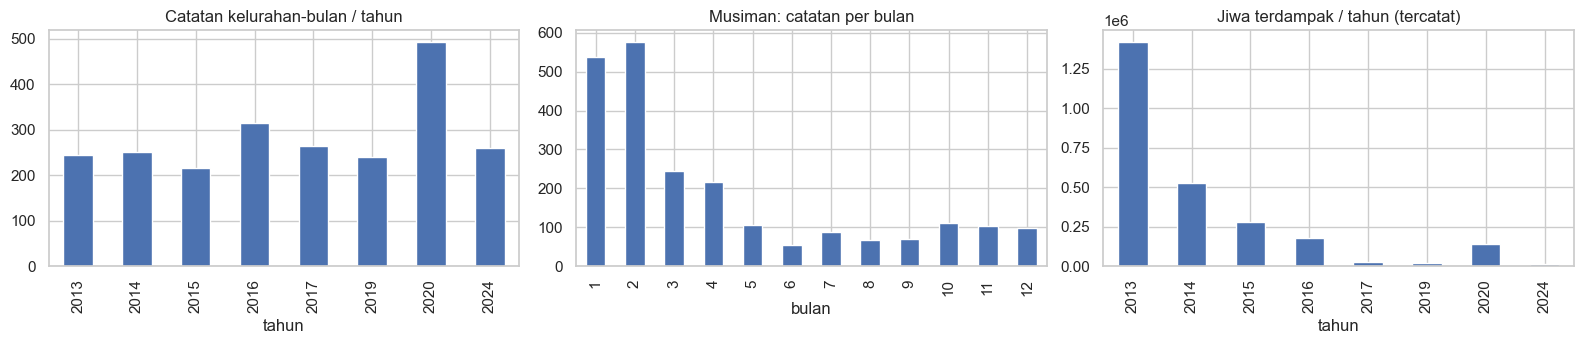

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
flood.groupby("tahun").size().plot.bar(ax=ax[0], title="Catatan kelurahan-bulan / tahun")
flood.dropna(subset=["bulan"]).groupby("bulan").size().reindex(range(1, 13), fill_value=0).plot.bar(ax=ax[1], title="Musiman: catatan per bulan")
flood.groupby("tahun").jiwa_terdampak.sum().plot.bar(ax=ax[2], title="Jiwa terdampak / tahun (tercatat)")
plt.tight_layout(); plt.show()

## C2. Distribusi keparahan kejadian

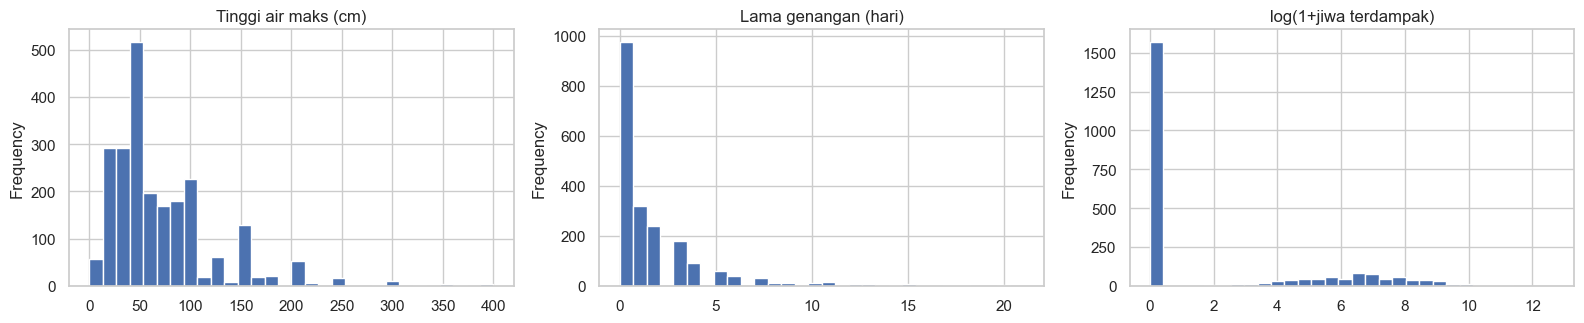

catatan dengan jiwa_terdampak = 0: 68.7 % -> kemungkinan 'tidak tercatat', bukan 'tanpa korban'


In [30]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.4))
flood.tinggi_max_cm.dropna().clip(upper=500).plot.hist(bins=30, ax=ax[0], title="Tinggi air maks (cm)")
flood.lama_hari.dropna().clip(upper=30).plot.hist(bins=30, ax=ax[1], title="Lama genangan (hari)")
np.log1p(flood.jiwa_terdampak).plot.hist(bins=30, ax=ax[2], title="log(1+jiwa terdampak)")
plt.tight_layout(); plt.show()
print("catatan dengan jiwa_terdampak = 0:", round((flood.jiwa_terdampak == 0).mean()*100, 1), "% -> kemungkinan 'tidak tercatat', bukan 'tanpa korban'")

## C3. Kecamatan paling terdampak

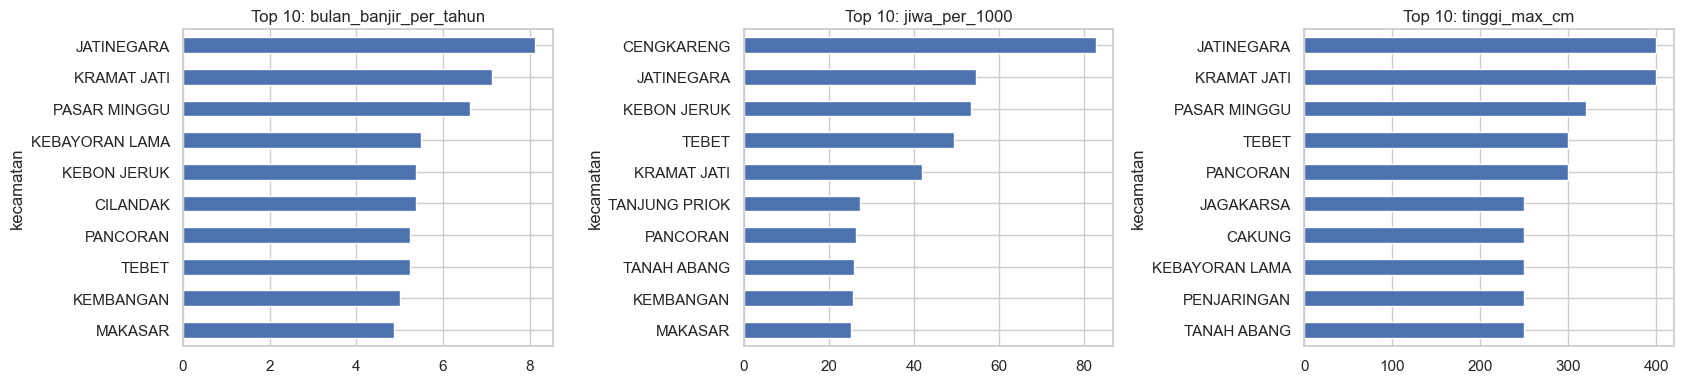

In [31]:
top = master.drop(index=[k for k in master.index if "SERIBU" in k])
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a_, col in zip(ax, ["bulan_banjir_per_tahun","jiwa_per_1000","tinggi_max_cm"]): top[col].sort_values().tail(10).plot.barh(ax=a_, title=f"Top 10: {col}")
plt.tight_layout(); plt.show()

## C4. Distribusi & korelasi fitur

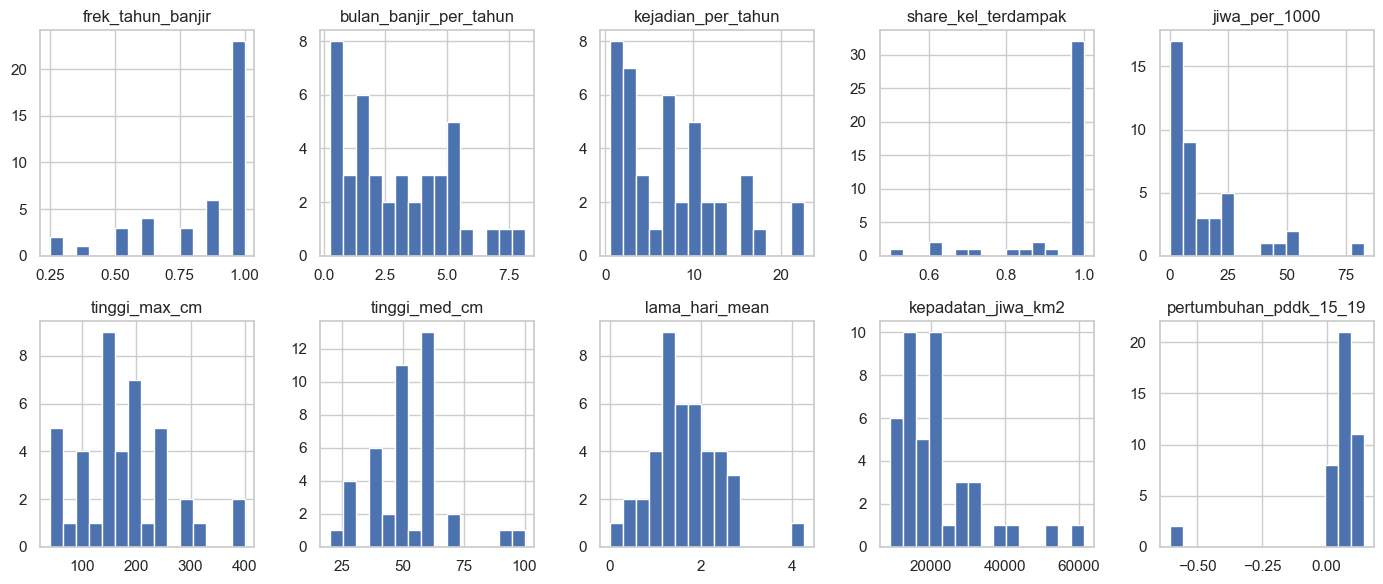

skewness: {'frek_tahun_banjir': -1.3, 'bulan_banjir_per_tahun': 0.5, 'kejadian_per_tahun': 0.9, 'share_kel_terdampak': -2.2, 'jiwa_per_1000': 1.9, 'tinggi_max_cm': 0.6, 'tinggi_med_cm': 0.7, 'lama_hari_mean': 0.7, 'kepadatan_jiwa_km2': 1.9, 'pertumbuhan_pddk_15_19': -4.0}


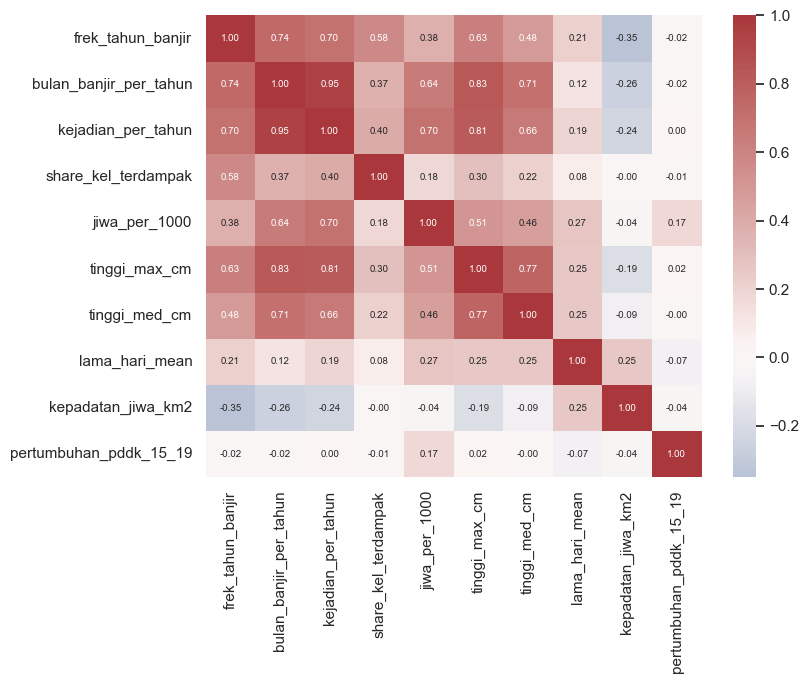

In [32]:
FEAT = ["frek_tahun_banjir","bulan_banjir_per_tahun","kejadian_per_tahun","share_kel_terdampak","jiwa_per_1000","tinggi_max_cm","tinggi_med_cm","lama_hari_mean","kepadatan_jiwa_km2","pertumbuhan_pddk_15_19"]
top[FEAT].hist(bins=15, figsize=(14, 6), layout=(2, 5)); plt.tight_layout(); plt.show()
print("skewness:", top[FEAT].skew().round(1).to_dict())
plt.figure(figsize=(8, 6)); sns.heatmap(top[FEAT].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, annot_kws={"size":7}); plt.show()

## C5. Peta

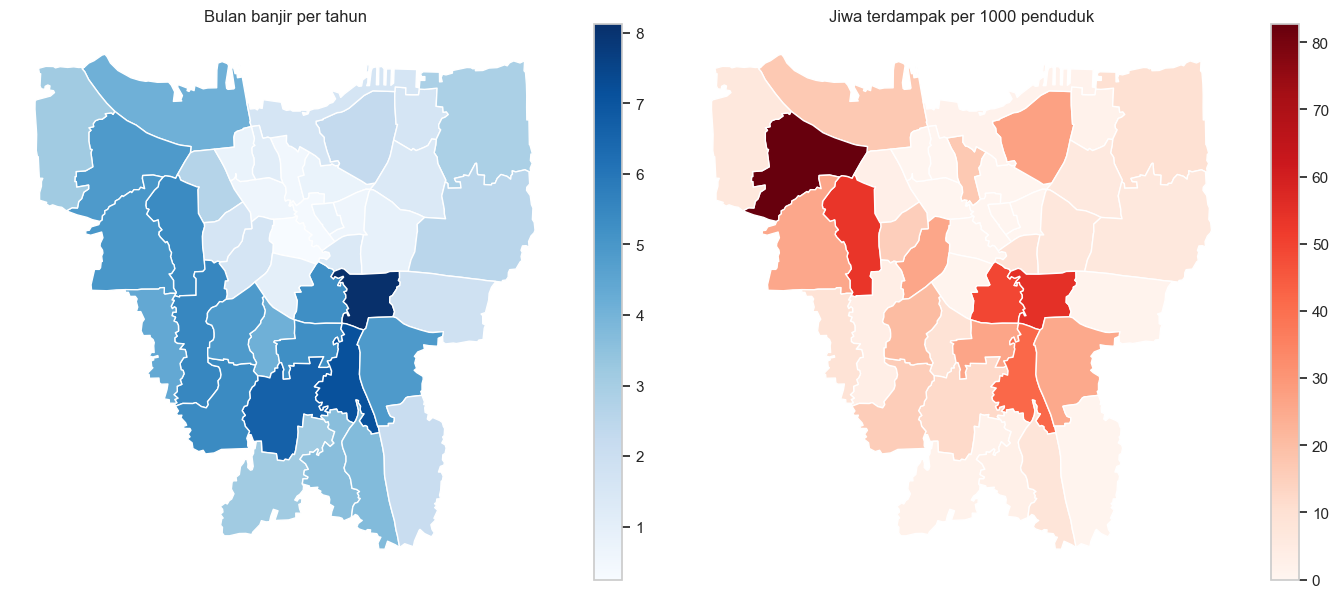

In [33]:
mp = pol.merge(master.reset_index()[["kecamatan","bulan_banjir_per_tahun","jiwa_per_1000"]], on="kecamatan", how="left")
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
mp.plot(column="bulan_banjir_per_tahun", cmap="Blues", legend=True, ax=ax[0], edgecolor="white"); ax[0].set_title("Bulan banjir per tahun"); ax[0].set_axis_off()
mp.plot(column="jiwa_per_1000", cmap="Reds", legend=True, ax=ax[1], edgecolor="white"); ax[1].set_title("Jiwa terdampak per 1000 penduduk"); ax[1].set_axis_off()
plt.tight_layout(); plt.show()

# D. Simpan

In [34]:
master.to_csv(DATA/"dki_master.csv"); print("tersimpan:", DATA/"dki_master.csv", master.shape)

tersimpan: ..\data\dki_master.csv (44, 19)
